This notebook will experiment with different models and different sets of features for those models. From the exploratory data analysis, we saw that there are varying distributions that will make modeling difficult.

In [1]:
import pandas as pd

df = pd.read_parquet("../data/processed/combined_english_with_tokens_and_features.parquet")

First, we need to split the data into training, validation, and testing. We have to split the data to make sure that the same conversations do not end up split between training and testing data. If not, there will be data leakage.

In [6]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["response_tokens"])
y = df["response_tokens"]

groups = df["conversation_id"].unique().to_numpy()

# 80% for training and validation, 20% test
dev_groups, test_groups = train_test_split(groups, test_size=0.2, random_state=42)

# 60% train, 20% validation
train_groups, val_groups = train_test_split(dev_groups, test_size=0.25, random_state=42)

train_mask = df["conversation_id"].isin(train_groups)
val_mask = df["conversation_id"].isin(val_groups)
test_mask = df["conversation_id"].isin(test_groups)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]
X_val = X.loc[val_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]
y_val = y.loc[val_mask]

Starting with simple dummy regressor as a baseline. The dummy regressor just predicts the mean of the response tokens. We will calculate this for both original response tokens and log response tokens. 

In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline MAE:", mean_absolute_error(y_test, baseline_pred))

Baseline MAE: 166.00130616336156


First, let's create a maximal linear model, with all features that do not introduce data leakage.

In [8]:
features = [
    "turn",
    "user_moderation_flag",
    "prompt_tokens",
    "history_tokens",
    "previous_response_tokens",
    "prompt_word_count",
    "prompt_char_count",
    "avg_word_length",
    "question_count",
    "newline_count",
    "has_numbers",
    "has_url",
    "has_code",
    "is_explanation",
    "is_summary",
    "is_code_request",
    "is_creative_writing",
    "is_list_request",
    "is_translation",
    "is_math",
    "requests_brief_answer",
    "requests_detailed_answer"
]

In [9]:
import statsmodels.api as sm
from sklearn.metrics import r2_score

X_max = sm.add_constant(X_train[features].astype(float))

max_model = sm.OLS(y_train, X_max).fit(cov_type="cluster", cov_kwds={"groups": df.loc[X_train.index, "conversation_id"]})

train_pred = max_model.predict(X_max).clip(lower=0)

print("Training MAE:", mean_absolute_error(y_train, train_pred))
print("Training R²:", r2_score(y_train, train_pred))

print(max_model.summary())

Training MAE: 181.26083124842637
Training R²: 0.7070581057632043
                            OLS Regression Results                            
Dep. Variable:        response_tokens   R-squared:                       0.647
Model:                            OLS   Adj. R-squared:                  0.647
Method:                 Least Squares   F-statistic:                     265.5
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:20:23   Log-Likelihood:            -3.5909e+06
No. Observations:              468129   AIC:                         7.182e+06
Df Residuals:                  468106   BIC:                         7.182e+06
Df Model:                          22                                         
Covariance Type:              cluster                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------

The statistically significant features are turn, user_moderation_flag, prompt_tokens, previous_response_tokens, question_count, has_numbers, has_url, has_Code, is_summary, is_code_request, and is_creative_writing.

 We will use all subset regression with the statistically significant features from the maximal feature and track performance.

In [10]:
features = [
    "turn",
    "user_moderation_flag",
    "prompt_tokens",
    "previous_response_tokens",
    "question_count",
    "has_numbers",
    "has_url",
    "has_code",
    "is_summary",
    "is_code_request",
    "is_creative_writing",
]

X_train_linear = X_train[features]
X_val_linear = X_val[features]
X_test_linear = X_test[features]

In [11]:
from itertools import combinations
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import pandas as pd

results = []

for n in range(1, len(features) + 1):
    print(f"{n} features")
    for subset in combinations(features, n):

        subset = list(subset)

        model = LinearRegression()
        model.fit(X_train_linear[subset], y_train)

        predictions = model.predict(X_val_linear[subset])
        predictions = predictions.clip(min=0)

        mae = mean_absolute_error(y_val, predictions)

        results.append({
            "model": model,
            "features": subset,
            "n_features": n,
            "val_mae": mae
        })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("val_mae")

print(results_df.head(10))

1 features
2 features
3 features
4 features
5 features
6 features
7 features
8 features
9 features
10 features
11 features
                   model                                           features  \
1482  LinearRegression()  [question_count, has_numbers, has_code, is_sum...   
1814  LinearRegression()  [question_count, has_numbers, has_url, has_cod...   
1776  LinearRegression()  [user_moderation_flag, question_count, has_num...   
1970  LinearRegression()  [user_moderation_flag, question_count, has_num...   
1804  LinearRegression()  [prompt_tokens, question_count, has_numbers, h...   
1978  LinearRegression()  [prompt_tokens, question_count, has_numbers, h...   
1960  LinearRegression()  [user_moderation_flag, prompt_tokens, question...   
2032  LinearRegression()  [user_moderation_flag, prompt_tokens, question...   
1692  LinearRegression()  [turn, question_count, has_numbers, has_code, ...   
1934  LinearRegression()  [turn, question_count, has_numbers, has_url, h...   

      n

Let's look at the best model, the best model for each size, and plot the performance of the model across subset sizes.

In [12]:
best_linear = results_df.iloc[0]

print("Best features:", best_linear["features"])
print("Number of features:", best_linear["n_features"])
print("Validation MAE:", best_linear["val_mae"])

Best features: ['question_count', 'has_numbers', 'has_code', 'is_summary', 'is_code_request', 'is_creative_writing']
Number of features: 6
Validation MAE: 147.99328305144985


In [13]:
best_by_size = (results_df.sort_values("val_mae").groupby("n_features").first())

print(best_by_size[["val_mae", "features"]])

               val_mae                                           features
n_features                                                               
1           152.172013                                  [is_code_request]
2           150.020514             [is_code_request, is_creative_writing]
3           149.200409  [is_summary, is_code_request, is_creative_writ...
4           148.607558  [has_code, is_summary, is_code_request, is_cre...
5           148.239107  [question_count, has_code, is_summary, is_code...
6           147.993283  [question_count, has_numbers, has_code, is_sum...
7           148.000979  [question_count, has_numbers, has_url, has_cod...
8           148.030228  [user_moderation_flag, question_count, has_num...
9           148.102579  [user_moderation_flag, prompt_tokens, question...
10          148.266593  [turn, user_moderation_flag, prompt_tokens, qu...
11          176.987037  [turn, user_moderation_flag, prompt_tokens, pr...


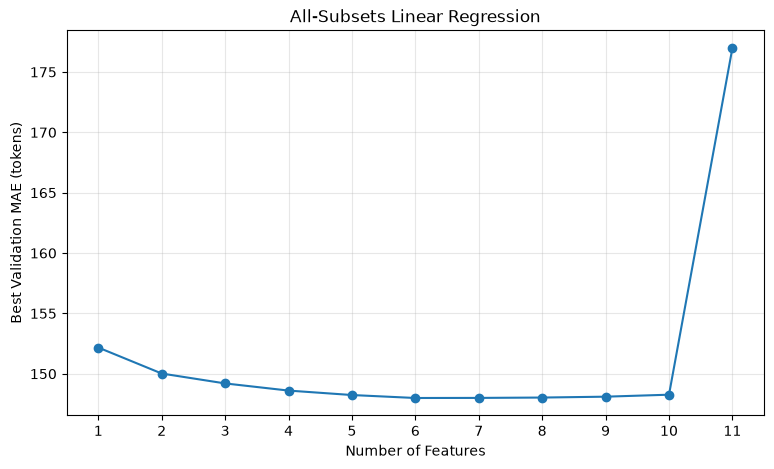

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(best_by_size.index, best_by_size["val_mae"], marker="o")

plt.xlabel("Number of Features")
plt.ylabel("Best Validation MAE (tokens)")
plt.title("All-Subsets Linear Regression")
plt.xticks(range(1, len(features) + 1))
plt.grid(alpha=0.3)

plt.show()

Interestingly, the best model from these features does not include the prompt_tokens or turn. I suspect that a reason for this is the very skewed nature of prompt_tokens and turn. So let's try the all subset regression but with some log transformations of the features.

In [ ]:
features = [
    "turn",
    "user_moderation_flag",
    "prompt_tokens",
    "previous_response_tokens",
    "question_count",
    "has_numbers",
    "has_url",
    "has_code",
    "is_summary",
    "is_code_request",
    "is_creative_writing",
]

X_train_linear_log = X_train[features]
X_val_linear_log = X_val[features]
X_test_linear_log = X_test[features]

X_train_linear_log["prompt_tokens"] = np.log1p(X_train_linear_log["prompt_tokens"])
X_val_linear_log["prompt_tokens"] = np.log1p(X_val_linear_log["prompt_tokens"])
X_test_linear_log["prompt_tokens"] = np.log1p(X_test_linear_log["prompt_tokens"])

X_train_linear_log["turn"] = np.log1p(X_train_linear_log["turn"])
X_val_linear_log["turn"] = np.log1p(X_val_linear_log["turn"])
X_test_linear_log["turn"] = np.log1p(X_test_linear_log["turn"])

X_train_linear_log["previous_response_tokens"] = np.log1p(X_train_linear_log["previous_response_tokens"])
X_val_linear_log["previous_response_tokens"] = np.log1p(X_val_linear_log["previous_response_tokens"])
X_test_linear_log["previous_response_tokens"] = np.log1p(X_test_linear_log["previous_response_tokens"])

In [27]:
from itertools import combinations
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import pandas as pd

results = []

for n in range(1, len(features) + 1):
    print(f"{n} features")
    for subset in combinations(features, n):

        subset = list(subset)

        model = LinearRegression()
        model.fit(X_train_linear_log[subset], y_train)

        predictions = model.predict(X_val_linear_log[subset])
        predictions = predictions.clip(min=0)

        mae = mean_absolute_error(y_val, predictions)

        results.append({
            "model": model,
            "features": subset,
            "n_features": n,
            "val_mae": mae
        })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("val_mae")

print(results_df.head(10))

1 features
2 features
3 features
4 features
5 features
6 features
7 features
8 features
9 features
10 features
11 features
                   model                                           features  \
1913  LinearRegression()  [turn, prompt_tokens, previous_response_tokens...   
2021  LinearRegression()  [turn, prompt_tokens, previous_response_tokens...   
1994  LinearRegression()  [turn, user_moderation_flag, prompt_tokens, pr...   
2020  LinearRegression()  [turn, prompt_tokens, previous_response_tokens...   
2040  LinearRegression()  [turn, user_moderation_flag, prompt_tokens, pr...   
2044  LinearRegression()  [turn, prompt_tokens, previous_response_tokens...   
2039  LinearRegression()  [turn, user_moderation_flag, prompt_tokens, pr...   
2046  LinearRegression()  [turn, user_moderation_flag, prompt_tokens, pr...   
1630  LinearRegression()  [turn, prompt_tokens, previous_response_tokens...   
1912  LinearRegression()  [turn, prompt_tokens, previous_response_tokens...   

      n

In [28]:
best_linear_log = results_df.iloc[0]

print("Best features:", best_linear_log["features"])
print("Number of features:", best_linear_log["n_features"])
print("Validation MAE:", best_linear_log["val_mae"])

Best features: ['turn', 'prompt_tokens', 'previous_response_tokens', 'question_count', 'has_code', 'is_summary', 'is_code_request', 'is_creative_writing']
Number of features: 8
Validation MAE: 143.94300164209903


In [29]:
best_by_size = (results_df.sort_values("val_mae").groupby("n_features").first())

print(best_by_size[["val_mae", "features"]])

               val_mae                                           features
n_features                                                               
1           152.172013                                  [is_code_request]
2           150.020514             [is_code_request, is_creative_writing]
3           148.996995  [turn, previous_response_tokens, is_code_request]
4           146.803519  [turn, previous_response_tokens, is_code_reque...
5           146.008838  [turn, previous_response_tokens, has_code, is_...
6           145.018774  [turn, prompt_tokens, previous_response_tokens...
7           144.405338  [turn, prompt_tokens, previous_response_tokens...
8           143.943002  [turn, prompt_tokens, previous_response_tokens...
9           143.954162  [turn, prompt_tokens, previous_response_tokens...
10          143.969778  [turn, user_moderation_flag, prompt_tokens, pr...
11          143.993677  [turn, user_moderation_flag, prompt_tokens, pr...


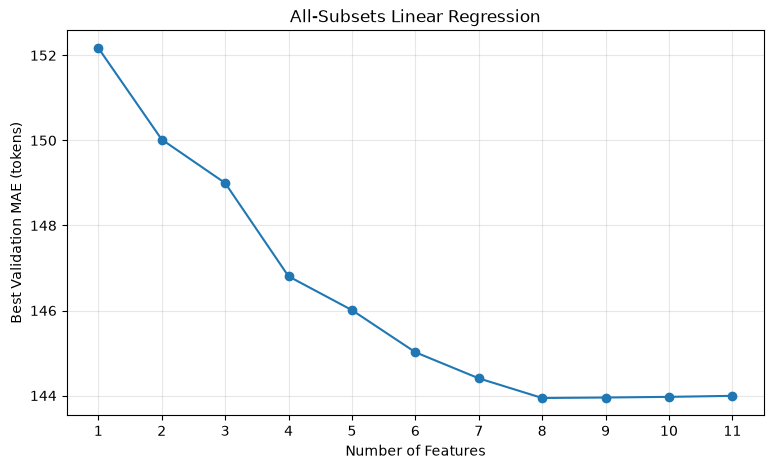

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(best_by_size.index, best_by_size["val_mae"], marker="o")

plt.xlabel("Number of Features")
plt.ylabel("Best Validation MAE (tokens)")
plt.title("All-Subsets Linear Regression")
plt.xticks(range(1, len(features) + 1))
plt.grid(alpha=0.3)

plt.show()

Adding these log transformations has slightly improved the accuracy of the model, with a MAE of ~143 now instead of ~147 without the transformations and subsequently without the prompt information. 

Importantly, the MAE of ~143 is better than the dummy regressor MAE of ~166.

We will also explore KNN. We will start with a maximal KNN model, with different values of K, and then decide on feature selection and feature engineering from there. We will train on only 10000 samples for the initial phase, as training is very expensive for KNN.

In [15]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error
import pandas as pd

features = [
    "turn",
    "user_moderation_flag",
    "prompt_tokens",
    "history_tokens",
    "previous_response_tokens",
    "prompt_word_count",
    "prompt_char_count",
    "avg_word_length",
    "question_count",
    "newline_count",
    "has_numbers",
    "has_url",
    "has_code",
    "is_explanation",
    "is_summary",
    "is_code_request",
    "is_creative_writing",
    "is_list_request",
    "is_translation",
    "is_math",
    "requests_brief_answer",
    "requests_detailed_answer"
]

k_values = [1, 3, 5, 10, 20, 50, 100]

results = []

X_sample = X_train.sample(n=50000, random_state=42)
y_sample = y_train.loc[X_sample.index]

X_val_sample = X_val.sample(n=10000, random_state=42)
y_val_sample = y_val.loc[X_val_sample.index]

for k in k_values:
    print(f"Evaluating {k} neighbor model")
    model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k, weights="uniform", n_jobs=-1))

    model.fit(X_sample[features], y_sample)

    predictions = model.predict(X_val_sample[features])

    mae = mean_absolute_error(y_val_sample, predictions)

    results.append({
        "model": model,
        "k": k,
        "val_mae": mae
    })

results_df = pd.DataFrame(results)

print(results_df)

Evaluating 1 neighbor model
Evaluating 3 neighbor model
Evaluating 5 neighbor model
Evaluating 10 neighbor model
Evaluating 20 neighbor model
Evaluating 50 neighbor model
Evaluating 100 neighbor model
                                               model    k     val_mae
0  (StandardScaler(), KNeighborsRegressor(n_jobs=...    1  136.660100
1  (StandardScaler(), KNeighborsRegressor(n_jobs=...    3  116.693267
2  (StandardScaler(), KNeighborsRegressor(n_jobs=...    5  114.948400
3  (StandardScaler(), KNeighborsRegressor(n_jobs=...   10  113.014620
4  (StandardScaler(), KNeighborsRegressor(n_jobs=...   20  112.069450
5  (StandardScaler(), KNeighborsRegressor(n_jobs=...   50  113.381570
6  (StandardScaler(), KNeighborsRegressor(n_jobs=...  100  114.746989


In [16]:
results_df_sorted = results_df.sort_values("val_mae")
best_knn = results_df_sorted.iloc[0]

best_knn["model"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['turn','user_moderation_flag','prompt_tokens',...,'is_math', 'requests_brief_answer','requests_detailed_answer']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


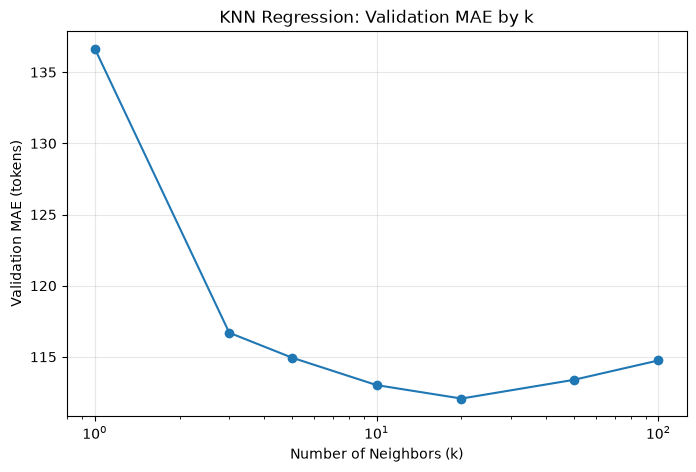

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(results_df["k"], results_df["val_mae"], marker="o")

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Validation MAE (tokens)")
plt.title("KNN Regression: Validation MAE by k")
plt.xscale("log")
plt.grid(alpha=0.3)

plt.show()

We will also try this with the log transformed features as well, like we did with the linear regression.

In [18]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error
import pandas as pd

features = [
    "turn",
    "user_moderation_flag",
    "prompt_tokens",
    "history_tokens",
    "previous_response_tokens",
    "prompt_word_count",
    "prompt_char_count",
    "avg_word_length",
    "question_count",
    "newline_count",
    "has_numbers",
    "has_url",
    "has_code",
    "is_explanation",
    "is_summary",
    "is_code_request",
    "is_creative_writing",
    "is_list_request",
    "is_translation",
    "is_math",
    "requests_brief_answer",
    "requests_detailed_answer"
]

k_values = [1, 3, 5, 10, 20, 50, 100]

results = []

X_sample = X_train.sample(n=50000, random_state=42)
y_sample = y_train.loc[X_sample.index]

X_val_sample = X_val.sample(n=10000, random_state=42)
y_val_sample = y_val.loc[X_val_sample.index]

for k in k_values:
    print(f"Evaluating {k} neighbor model")
    model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k, weights="uniform", n_jobs=-1))

    train = X_sample[features]
    train["prompt_tokens"] = np.log1p(train["prompt_tokens"])
    train["turn"] = np.log1p(train["turn"])
    train["previous_response_tokens"] = np.log1p(train["previous_response_tokens"])

    model.fit(train, y_sample)

    val = X_val_sample[features]
    val["prompt_tokens"] = np.log1p(val["prompt_tokens"])
    val["turn"] = np.log1p(val["turn"])
    val["previous_response_tokens"] = np.log1p(val["previous_response_tokens"])

    predictions = model.predict(val)

    mae = mean_absolute_error(y_val_sample, predictions)

    results.append({
        "model": model,
        "k": k,
        "val_mae": mae
    })

results_df = pd.DataFrame(results)

print(results_df)

Evaluating 1 neighbor model
Evaluating 3 neighbor model
Evaluating 5 neighbor model
Evaluating 10 neighbor model
Evaluating 20 neighbor model
Evaluating 50 neighbor model
Evaluating 100 neighbor model
                                               model    k     val_mae
0  (StandardScaler(), KNeighborsRegressor(n_jobs=...    1  136.644200
1  (StandardScaler(), KNeighborsRegressor(n_jobs=...    3  118.316867
2  (StandardScaler(), KNeighborsRegressor(n_jobs=...    5  115.602160
3  (StandardScaler(), KNeighborsRegressor(n_jobs=...   10  113.247690
4  (StandardScaler(), KNeighborsRegressor(n_jobs=...   20  112.936470
5  (StandardScaler(), KNeighborsRegressor(n_jobs=...   50  113.662546
6  (StandardScaler(), KNeighborsRegressor(n_jobs=...  100  115.010561


In [19]:
results_df_sorted = results_df.sort_values("val_mae")
best_knn_log = results_df_sorted.iloc[0]

best_knn_log["model"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['turn','user_moderation_flag','prompt_tokens',...,'is_math', 'requests_brief_answer','requests_detailed_answer']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


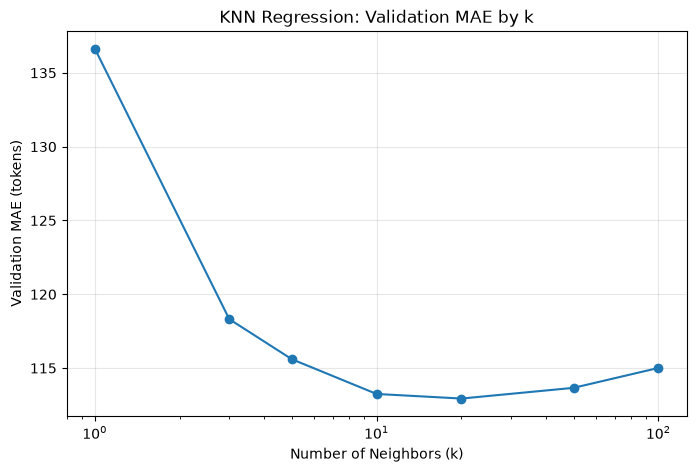

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(results_df["k"], results_df["val_mae"], marker="o")

plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Validation MAE (tokens)")
plt.title("KNN Regression: Validation MAE by k")
plt.xscale("log")
plt.grid(alpha=0.3)

plt.show()

The performance did not improve with by adding the log transformations. Interestingly, in both versions of the KNN models, k = 20 had the best performance. Now, we will try models with different subsets of features. There are too many possible combinations of subsets, so we will generate 100 random subsets of features to test.

In [22]:
import numpy as np

rng = np.random.default_rng(42)

n_subsets = 100

feature_subsets = []

for _ in range(n_subsets):
    n_features = rng.integers(3, len(features) + 1)

    subset = sorted(rng.choice(features, size=n_features, replace=False).tolist())

    feature_subsets.append(subset)

In [23]:
k_values = [20]

X_sample = X_train.sample(n=50000, random_state=42)
y_sample = y_train.loc[X_sample.index]

X_val_sample = X_val.sample(n=10000, random_state=42)
y_val_sample = y_val.loc[X_val_sample.index]

results = []

for i, subset in enumerate(feature_subsets):
    print(f"Evaluating {i} subset")
    for k in k_values:

        model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k, weights="uniform", n_jobs=-1))

        model.fit(X_sample[subset], y_sample)

        predictions = model.predict(X_val_sample[subset])

        mae = mean_absolute_error(y_val_sample, predictions)

        results.append({
            "features": subset,
            "n_features": len(subset),
            "k": k,
            "val_mae": mae
        })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("val_mae")

display(results_df.head(10))

Evaluating 0 subset
Evaluating 1 subset
Evaluating 2 subset
Evaluating 3 subset
Evaluating 4 subset
Evaluating 5 subset
Evaluating 6 subset
Evaluating 7 subset
Evaluating 8 subset
Evaluating 9 subset
Evaluating 10 subset
Evaluating 11 subset
Evaluating 12 subset
Evaluating 13 subset
Evaluating 14 subset
Evaluating 15 subset
Evaluating 16 subset
Evaluating 17 subset
Evaluating 18 subset
Evaluating 19 subset
Evaluating 20 subset
Evaluating 21 subset
Evaluating 22 subset
Evaluating 23 subset
Evaluating 24 subset
Evaluating 25 subset
Evaluating 26 subset
Evaluating 27 subset
Evaluating 28 subset
Evaluating 29 subset
Evaluating 30 subset
Evaluating 31 subset
Evaluating 32 subset
Evaluating 33 subset
Evaluating 34 subset
Evaluating 35 subset
Evaluating 36 subset
Evaluating 37 subset
Evaluating 38 subset
Evaluating 39 subset
Evaluating 40 subset
Evaluating 41 subset
Evaluating 42 subset
Evaluating 43 subset
Evaluating 44 subset
Evaluating 45 subset
Evaluating 46 subset
Evaluating 47 subset
Ev

,features,n_features,k,val_mae
69,"[has_code, has_numbers, has_url, is_code_reque...",19,20,111.393820
10,"[avg_word_length, has_code, has_numbers, has_u...",17,20,111.667660
46,"[avg_word_length, has_code, has_numbers, has_u...",22,20,112.065200
53,"[avg_word_length, has_code, has_numbers, has_u...",22,20,112.065200
81,"[avg_word_length, has_code, has_numbers, has_u...",22,20,112.065200
91,"[avg_word_length, has_code, has_numbers, has_u...",22,20,112.065200
95,"[avg_word_length, has_code, has_numbers, has_u...",22,20,112.065200
33,"[avg_word_length, has_code, has_numbers, has_u...",22,20,112.065200
3,"[avg_word_length, has_code, has_numbers, has_u...",20,20,112.217975
22,"[avg_word_length, has_code, has_numbers, histo...",21,20,112.221855


In [24]:
max_features = 22

results_df_filtered = results_df[(results_df["n_features"] != max_features) |(~results_df["n_features"].eq(max_features).duplicated())]

display(results_df_filtered.head(10))

,features,n_features,k,val_mae
69,"[has_code, has_numbers, has_url, is_code_reque...",19,20,111.393820
10,"[avg_word_length, has_code, has_numbers, has_u...",17,20,111.667660
46,"[avg_word_length, has_code, has_numbers, has_u...",22,20,112.065200
3,"[avg_word_length, has_code, has_numbers, has_u...",20,20,112.217975
22,"[avg_word_length, has_code, has_numbers, histo...",21,20,112.221855
59,"[avg_word_length, has_code, has_numbers, has_u...",21,20,112.281210
47,"[avg_word_length, has_code, has_numbers, has_u...",19,20,112.390155
38,"[avg_word_length, has_code, has_numbers, has_u...",19,20,112.528435
55,"[avg_word_length, has_code, has_numbers, has_u...",20,20,112.564150
32,"[avg_word_length, has_numbers, has_url, histor...",14,20,112.682100


Interestingly, the third best model has all features. So, we will train a KNN model with all features.

In [25]:
knn_model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=20, weights="uniform", n_jobs=-1))

knn_model.fit(X_train[features], y_train)

train_predictions = knn_model.predict(X_train[features])
val_predictions = knn_model.predict(X_val[features])

train_mae = mean_absolute_error(y_train, train_predictions)
val_mae = mean_absolute_error(y_val, val_predictions)

print(f"Training MAE: {train_mae:.2f}")
print(f"Validation MAE: {val_mae:.2f}")

Training MAE: 99.69
Validation MAE: 104.97


In [32]:
features = [
    "turn",
    "user_moderation_flag",
    "prompt_tokens",
    "history_tokens",
    "previous_response_tokens",
    "prompt_word_count",
    "prompt_char_count",
    "avg_word_length",
    "question_count",
    "newline_count",
    "has_numbers",
    "has_url",
    "has_code",
    "is_explanation",
    "is_summary",
    "is_code_request",
    "is_creative_writing",
    "is_list_request",
    "is_translation",
    "is_math",
    "requests_brief_answer",
    "requests_detailed_answer"
]

In [30]:
def calculate_aggregate_stats(predictions, truth):
    predictions = np.maximum(predictions, 0)
    total_true_response_tokens = np.sum(truth)
    total_predicted_response_tokens = np.sum(predictions)
    aggregate_error = ((total_predicted_response_tokens - total_true_response_tokens) / total_true_response_tokens) * 100

    return total_true_response_tokens, total_predicted_response_tokens, aggregate_error


In [ ]:
baseline_pred = baseline.predict(X_test)
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)
baseline_total_true, baseline_total_pred, baseline_aggregate_error = calculate_aggregate_stats(baseline_pred, y_test)

linear_pred = best_linear["model"].predict(X_test[best_linear["features"]])
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_r2 = r2_score(y_test, linear_pred)
linear_total_true, linear_total_pred, linear_aggregate_error = calculate_aggregate_stats(linear_pred, y_test)

linear_log_pred = best_linear_log["model"].predict(X_test_linear_log[best_linear_log["features"]])
linear_log_mae = mean_absolute_error(y_test, linear_log_pred)
linear_log_r2 = r2_score(y_test, linear_log_pred)
linear_log_total_true, linear_log_total_pred, linear_log_aggregate_error = (calculate_aggregate_stats(linear_log_pred, y_test))

knn_pred = knn_model.predict(X_test[features])
knn_mae = mean_absolute_error(y_test, knn_pred)
knn_r2 = r2_score(y_test, knn_pred)
knn_total_true, knn_total_pred, knn_aggregate_error = calculate_aggregate_stats(knn_pred, y_test)

results = {
    "Model": ["Baseline", "Linear Regression (no transformations)", "Linear Regression (with log transformations)", "KNN"],
    "MAE": [baseline_mae, linear_mae, linear_log_mae, knn_mae],
    "R2": [baseline_r2, linear_r2, linear_log_r2, knn_r2],
    "Total Predicted Tokens": [baseline_total_pred, linear_total_pred, linear_log_total_pred, knn_total_pred],
    "Signed Aggregate Error %": [baseline_aggregate_error, linear_aggregate_error, linear_log_aggregate_error, knn_aggregate_error]
}

results_df = pd.DataFrame(results)
display(results_df)

,Model,MAE,R2,Total Predicted Tokens,Signed Aggregate Erorr %
0,Baseline,166.001306,-0.000054,3.577736e+07,-3.437031
1,Linear Regression (no transformations),157.833113,0.002578,3.575975e+07,-3.484575
2,Linear Regression (with log transformations),154.029597,0.004303,3.580130e+07,-3.372426
3,KNN,108.154114,0.822245,3.632490e+07,-1.959217


In [35]:
print(results_df.to_latex(index=False, float_format="%.3f"))

\begin{tabular}{lrrrr}
\toprule
Model & MAE & R2 & Total Predicted Tokens & Signed Aggregate Erorr % \\
\midrule
Baseline & 166.001 & -0.000 & 35777361.074 & -3.437 \\
Linear Regression (no transformations) & 157.833 & 0.003 & 35759745.871 & -3.485 \\
KNN & 108.154 & 0.822 & 36324903.300 & -1.959 \\
\bottomrule
\end{tabular}

